[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L3/BA_L3_oos_var_btc/BA_L3_oos_var_btc.ipynb)

# BA_L3_oos_var_btc: Bitcoin VaR out of sample

*Quantlet of Lecture 3, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

The four one-day VaR 1% methods of the backtest (Normal from 2018, historical simulation 500 days, EWMA, GARCH(1,1)-t with parameters frozen on 18 September 2026) rolled forward over 19 September - 23 October 2026 for Bitcoin: VaR paths, hits and mean capital per 1 million USD.

In [1]:
# packages that are not preinstalled on Colab
import importlib, subprocess, sys
for pkg in ['arch']:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)

In [2]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [3]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [4]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

**Out of sample.** The GARCH-t parameters are frozen on 18 September 2026 (day $T$); only the filter is updated with each new return,
$$ \hat\sigma^2_{t|t-1} = \hat\omega + \hat\alpha\,(r_{t-1} - \hat\mu)^2 + \hat\beta\,\hat\sigma^2_{t-1|t-2}, \qquad t = T+1, \dots, T+H, $$
over 19 September – 23 October 2026: 35 calendar days for crypto, 25 trading days for the S&P 500 and gold.

**Methods, rolled forward day by day.** Normal on all returns from 2018 to the previous day; historical simulation (HS) on the last 500 days; EWMA ($\lambda = 0.94$, Normal quantile); GARCH-t with the parameters estimated on 1 January 2018 – 18 September 2026 and the filter updated daily.
VaR is a positive loss, $\mathrm{VaR}_{1\%} = -q_{0.01}$; the capital for a long position of 1 million USD is $10^6(1 - e^{-\mathrm{VaR}/100})$.

**How to read.** Bars: Bitcoin daily log returns; lines: minus the VaR 1% of each method. A hit is a bar below a line.

In [5]:
from scipy import stats
from arch import arch_model

END = '2026-09-18'                      # last day of the estimation sample
ASSETS = {'Bitcoin': ('BTC-USD.CC', 365, BTC), 'Ethereum': ('ETH-USD.CC', 365, ETH),
          'S&P 500': ('GSPC.INDX', 252, BLUE), 'Gold': ('XAUUSD.FOREX', 252, GOLD)}


def closes(sym, end):
    # daily closes; S&P 500 and gold: Monday-Friday only, repeated closes removed
    p = daily(sym, end)
    if sym.endswith(('.INDX', '.FOREX')):
        p = p[p.index.dayofweek < 5]
        p = p[p.diff().ne(0)]
    return p


def log_returns(sym, start='2018-01-01'):
    # daily log returns in %, from `start` to END
    p = closes(sym, END)
    return (100 * np.log(p).diff()).dropna().loc[start:]


R = {k: log_returns(ASSETS[k][0]) for k in ['Bitcoin']}
print({k: f'{len(r)} days, {r.index[0].date()} - {r.index[-1].date()}' for k, r in R.items()})

{'Bitcoin': '3183 days, 2018-01-01 - 2026-09-18'}


In [6]:
# GARCH(1,1) with Student-t errors, estimated by maximum likelihood (package arch)
fits = {k: arch_model(r, mean='Constant', vol='GARCH', p=1, q=1, dist='t').fit(disp='off') for k, r in R.items()}
pd.DataFrame({k: {'mu': g.params['mu'], 'omega': g.params['omega'], 'alpha': g.params['alpha[1]'], 'beta': g.params['beta[1]'],
                   'alpha + beta': g.params['alpha[1]'] + g.params['beta[1]'], 'nu': g.params['nu']} for k, g in fits.items()}).round(4)

,Bitcoin
mu,0.0563
omega,0.1442
alpha,0.0761
beta,0.9239
alpha + beta,1.0000
nu,3.1260


In [7]:
lam = 0.94     # RiskMetrics decay


def ewma_forecasts(r, lam=lam):
    # one-step EWMA variance forecasts: value at t = forecast for day t made at the end of day t-1;
    # started at the variance of the first 250 days; the last element is the forecast for the day after the sample
    v = r.iloc[:250].var(); out = []
    for x in r.values:
        out.append(v)
        v = lam * v + (1 - lam) * x ** 2
    return pd.Series(out, index=r.index), v

p1, p25 = 0.01, 0.025
z1, z25 = stats.norm.ppf(p1), stats.norm.ppf(p25)


def es_factor(q, p, nu):
    # f_nu(q) / p * (nu + q^2) / (nu - 1): the ES multiplier of the standard Student-t
    return stats.t.pdf(q, nu) / p * (nu + q ** 2) / (nu - 1)

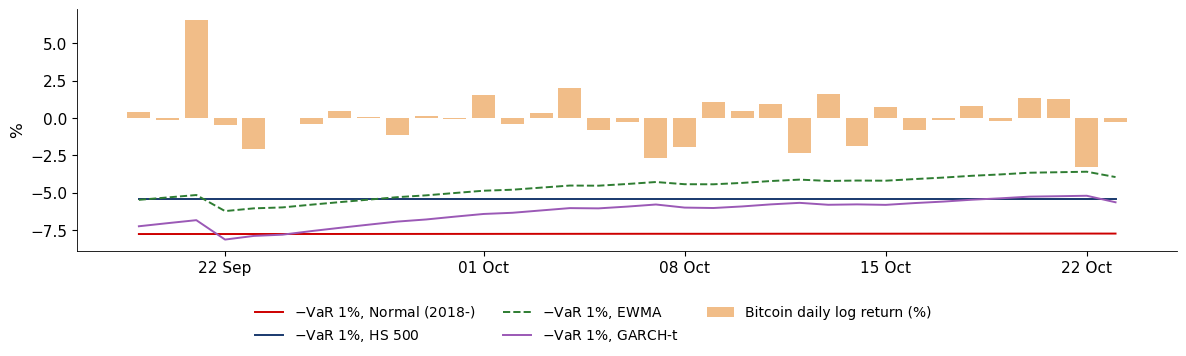

In [8]:
import matplotlib.dates as mdates
T0, T1 = pd.Timestamp(END), pd.Timestamp('2026-10-23')
full_o = (100 * np.log(daily('BTC-USD.CC', T1)).diff()).dropna().loc['2015-01-01':]
oos = full_o.loc[T0 + pd.Timedelta(days=1):]
prm = fits['Bitcoin'].params; nu_b = prm['nu']; sc_b = np.sqrt((nu_b - 2) / nu_b)
r_all = full_o.loc['2018-01-01':]
sigG = arch_model(r_all, mean='Constant', vol='GARCH', p=1, q=1, dist='t').fix(prm).conditional_volatility.loc[oos.index]
loc_o = {t_: i for i, t_ in enumerate(full_o.index)}
ewv = ewma_forecasts(full_o)[0]
VO = pd.DataFrame(index=oos.index)
for t_ in oos.index:
    i = loc_o[t_]; w500 = full_o.iloc[i - 500:i]
    hist = full_o.loc['2018-01-01':full_o.index[i - 1]]
    VO.loc[t_, 'Normal (2018-)'] = -(hist.mean() + hist.std() * z1)
    VO.loc[t_, 'HS 500'] = -w500.quantile(p1)
    VO.loc[t_, 'EWMA'] = -np.sqrt(ewv[t_]) * z1
    VO.loc[t_, 'GARCH-t'] = -(prm['mu'] + sigG[t_] * sc_b * stats.t.ppf(p1, nu_b))

fig, ax = plt.subplots(figsize=(12, 3.6))
ax.bar(oos.index, oos, width=0.8, color=BTC, alpha=0.6, label='Bitcoin daily log return (%)')
for m_, col, ls in [('Normal (2018-)', RED, '-'), ('HS 500', BLUE, '-'), ('EWMA', GREEN, '--'), ('GARCH-t', ETH, '-')]:
    ax.plot(VO.index, -VO[m_], color=col, ls=ls, lw=1.4, label=f'$-$VaR 1%, {m_}')
ax.set_ylabel('%')
ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=[1, 8, 15, 22]))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
legend_below(fig, ncol=3); fig.tight_layout(rect=(0, 0.17, 1, 1))
save_fig(fig, 'ba_oos_var_btc')

**Key numbers** (as on the slide): Bitcoin one-day VaR 1% over the 35 days.

In [9]:
print(f'days: {len(oos)}; expected hits = {p1 * len(oos):.2f}')
w_ = oos.idxmin()
print(f'worst day {w_.date()}: {oos.min():.2f}%, which is {-oos.min() / VO.loc[w_, "GARCH-t"]:.2f} of that day\'s GARCH-t VaR')
pd.DataFrame({'mean VaR 1% (%)': VO.mean(), 'min VaR (%)': VO.min(), 'max VaR (%)': VO.max(),
              'hits': (oos.values[:, None] < -VO.values).sum(axis=0),
              'mean capital, USD per 1m': (1e6 * (1 - np.exp(-VO / 100))).mean()}).round(2)

days: 35; expected hits = 0.35
worst day 2026-10-22: -3.27%, which is 0.63 of that day's GARCH-t VaR


,mean VaR 1% (%),min VaR (%),max VaR (%),hits,"mean capital, USD per 1m"
Normal (2018-),7.73,7.72,7.75,0,74427.81
HS 500,5.43,5.43,5.43,0,52854.34
EWMA,4.66,3.59,6.22,0,45500.23
GARCH-t,6.28,5.19,8.12,0,60870.50
